# Individuell uppgift – Hälsostudie, Del 1

I den här notebooken analyserar jag data från en hälsostudie med 800 deltagare.
Analysen omfattar beskrivande statistik, grafer, simulering, konfidensintervall och hypotesprövning.

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(42)

# Inställningar för diagram
plt.rcParams.update({
    "figure.figsize": (8, 5),
    "figure.constrained_layout.use": True,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=["steelblue", "darkorange", "seagreen"]),
})

Att centralisera grafinställningarna undviker kodupprepning och gör den visuella stilen enhetlig.
Källa: https://matplotlib.org/stable/users/explain/customizing.html

## 1. Inläsning och första granskning av data

Kontroll av datasetets storlek, datatyper, saknade värden, dubbletter och vilka värden de kategoriska variablerna har.

**Observationer:**
- Datasetet innehåller 800 deltagare och 9 kolumner.
- Inga saknade värden förekommer i någon kolumn.
- Inga dubblerade ID:n och rader.
- Variablerna `sex` och `smoker` har endast två kategorier vardera, och
  `disease` är binär (0/1), vilket stämmer med uppgiftsbeskrivningen.
- Åldern sträcker sig mellan 18 och 90 år, medelvärdet för kolesterolnivå är ca 4,9 mmol/L, och medelvärdet för systoliskt blodtryck är ca 149 mmHg

**Anteckningar om kolesterolnivå och systoliskt blodtryck**
- Uppgiften anger endast "kolesterolnivå (mmol/L)". Eftersom medelvärdet (ca 4,9 mmol/L)
ligger nära vad som är typiskt för totalkolesterol, tolkar jag variabeln som
totalkolesterol. Det är en antagen tolkning och inte något som framgår av datan.
Som referens anges ett önskvärt värde för totalkolesterol ofta som under ca 5 mmol/L
(källa: https://www.1177.se/sjukdomar--besvar/hjarta-och-blodkarl/blodkarl/hoga-blodfetter/).

- Uppgiften anger blodtrycket som "systolic_bp" (mmHg). Medelvärdet i datasetet (ca 149 mmHg) ligger
högt jämfört med vad som anses normalt. Värden på 140 mmHg eller däröver räknas
vanligtvis som högt blodtryck (källa: https://www.1177.se/sjukdomar--besvar/hjarta-och-blodkarl/blodtryck/hogt-blodtryck/).

In [21]:
df = pd.read_csv("data/health_study_dataset.csv")

display(df.head())
df.info()
display(df.describe())

print("Antal dubbletter av id:", df["id"].duplicated().sum())
print("Antal dubbletter av rader (exklusive id):", df.drop(columns="id").duplicated().sum())

print("\nFördelning av kön:")
print(df["sex"].value_counts())
print("\nFördelning av rökare:")
print(df["smoker"].value_counts())
print("\nFördelning av sjukdom (0 = frisk, 1 = sjuk):")
print(df["disease"].value_counts())

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB


,id,age,height,weight,systolic_bp,cholesterol,disease
count,800.0000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000
mean,400.5000,49.426250,171.849250,73.413000,149.178625,4.929150,0.058750
std,231.0844,14.501118,9.804259,13.685059,12.793360,0.848413,0.235303
min,1.0000,18.000000,144.400000,33.700000,106.800000,2.500000,0.000000
25%,200.7500,39.000000,164.775000,64.800000,140.900000,4.327500,0.000000
50%,400.5000,50.000000,171.350000,73.200000,149.400000,4.970000,0.000000
75%,600.2500,59.000000,178.925000,82.600000,157.600000,5.482500,0.000000
max,800.0000,90.000000,200.400000,114.400000,185.900000,7.880000,1.000000


Antal dubbletter av id: 0
Antal dubbletter av rader (exklusive id): 0

Fördelning av kön:
sex
F    403
M    397
Name: count, dtype: int64

Fördelning av rökare:
smoker
No     587
Yes    213
Name: count, dtype: int64

Fördelning av sjukdom (0 = frisk, 1 = sjuk):
disease
0    753
1     47
Name: count, dtype: int64


## 2. Beskrivande statistik

Medelvärde, median, minimum och maximum beräknas för de numeriska variablerna
age, weight, height, systolic_bp och cholesterol.

**Observationer:**
- Medelvärde och median ligger väldigt nära för värje variabel, som är ett karakteristik av  normalfördelning.
- Minsta värdet för vikt är 33.7 som är ganska ovanligt för vuxna, det bör undersökas vidare.
- Med referenser för normal kolesterol och systoliskt blodtryck som ligger ungefär < 5 mmol/L och < 140 mmHg respektive, medelvärden av ca 4.9 mmol/L och 149 mmHg visar att många undersökade ligger över normala gränsen.

In [22]:
num_col = ["age", "weight", "height", "systolic_bp", "cholesterol"]

descriptive_stats = df[num_col].agg(["mean", "median", "min", "max"]).T
descriptive_stats.columns = ["Medelvärde", "Median", "Min", "Max"]

display(descriptive_stats.round(2))

,Medelvärde,Median,Min,Max
age,49.43,50.00,18.0,90.00
weight,73.41,73.20,33.7,114.40
height,171.85,171.35,144.4,200.40
systolic_bp,149.18,149.40,106.8,185.90
cholesterol,4.93,4.97,2.5,7.88


## Studiedesign och analysplan

- **Population:** Från beskrivande statistik kan man förstå att populationen omfattar vuxna personer i åldern 18–90 år.
- **Jämförelse mot kontrollgrupp:** Detta är inte ett experiment utan en
  observationsstudie. Jag jämför rökare med icke-rökare (kontrollgrupp). Ingen
  tilldelning har gjorts, så resultaten visar samband och inte orsakssamband.
- **Primär mätvariabel:** systolic_bp (mmHg).
- **Utfallets typ:** Kontinuerligt (systolic_bp). Variabeln disease är binär och
  analyseras separat i simuleringsdelen.
- **Praktiskt betydelsefull skillnad:** Jag valde 5 mmHg som praktiskt betydelsefull skillnad eftersom en sänkning på 5 mmHg anses vara kliniskt relevant enligt följande riktlinjer (källa: https://www.cochranelibrary.com/cdsr/doi/10.1002/14651858.CD015092.pub2/supplementarymaterials/CD015092-SUP-07-other.html).
- **Signifikansnivå:** α = 0,05.
- **Ensidigt eller tvåsidigt test:** Hypotesen "rökare har högre medelblodtryck" har
  en bestämd riktning, så jag använder ett ensidigt test.
- **Stickprovsstorlek:** 800 deltagare, varav 213 rökare och 587 icke-rökare.
- **Sekundära analyser:** Konfidensintervall för medelblodtrycket med två metoder,
  andel sjuka per rökstatus samt regressionsanalyser i del 2. Kolesterol används
  endast beskrivande och i grafer, och testas inte formellt. Dessa analyser
  betraktas som utforskande och inte som bekräftande.

## 3. Grafer

Fyra grafer används för att få en första bild av datan:
- fördelningen av blodtryck
- viktfördelningen per kön
- andelen rökare
- andelen sjuka per rökstatus

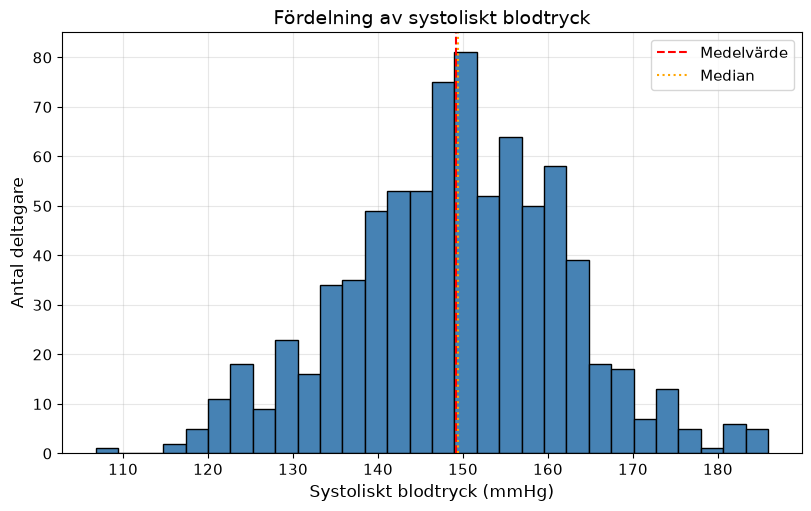

In [23]:
fig, ax = plt.subplots()

ax.hist(df["systolic_bp"], bins=30, edgecolor="black")
ax.axvline(df["systolic_bp"].mean(), color="red", linestyle="--", label="Medelvärde")
ax.axvline(df["systolic_bp"].median(), color="orange", linestyle=":", label="Median")

ax.set_title("Fördelning av systoliskt blodtryck")
ax.set_xlabel("Systoliskt blodtryck (mmHg)")
ax.set_ylabel("Antal deltagare")
ax.legend()

plt.show()

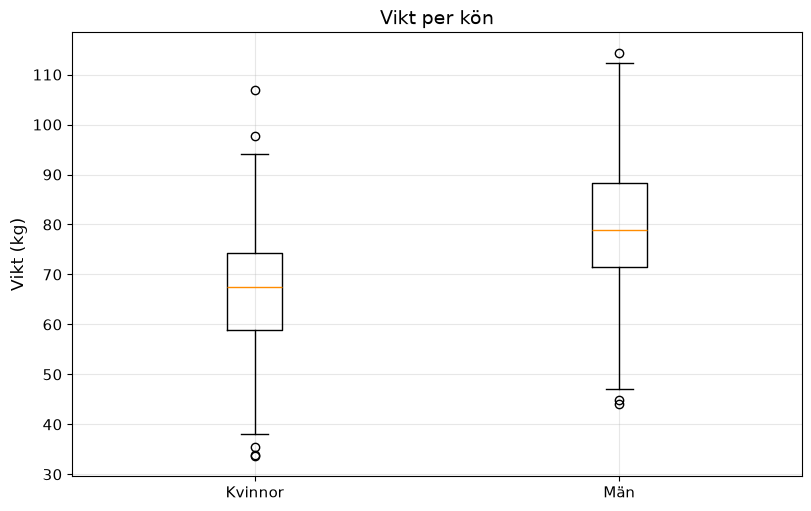

In [24]:
weight_female = df.loc[df["sex"] == "F", "weight"]
weight_male = df.loc[df["sex"] == "M", "weight"]

fig, ax = plt.subplots()

ax.boxplot([weight_female, weight_male])
ax.set_xticks([1, 2])
ax.set_xticklabels(["Kvinnor", "Män"])

ax.set_title("Vikt per kön")
ax.set_ylabel("Vikt (kg)")

plt.show()

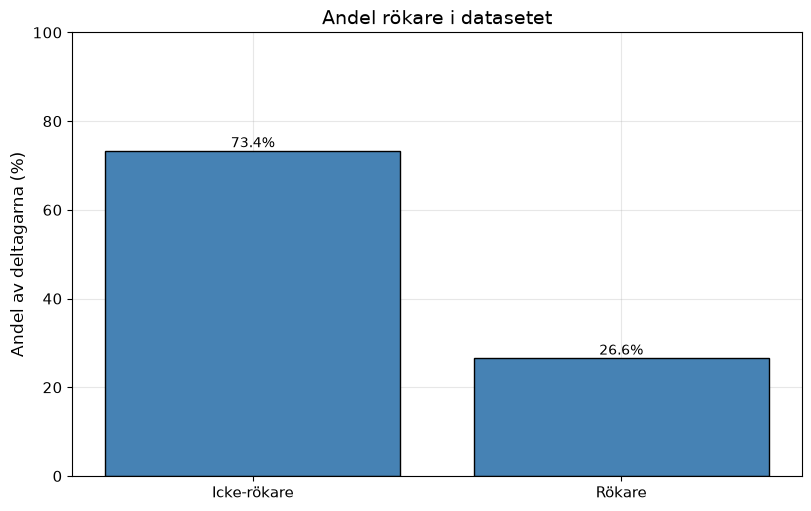

In [25]:
smoker_share = df["smoker"].value_counts(normalize=True) * 100
smoker_share = smoker_share.reindex(["No", "Yes"])

fig, ax = plt.subplots()

bars = ax.bar(["Icke-rökare", "Rökare"], smoker_share.values, edgecolor="black")
ax.bar_label(bars, fmt="%.1f%%")

ax.set_title("Andel rökare i datasetet")
ax.set_ylabel("Andel av deltagarna (%)")
ax.set_ylim(0, 100)

plt.show()

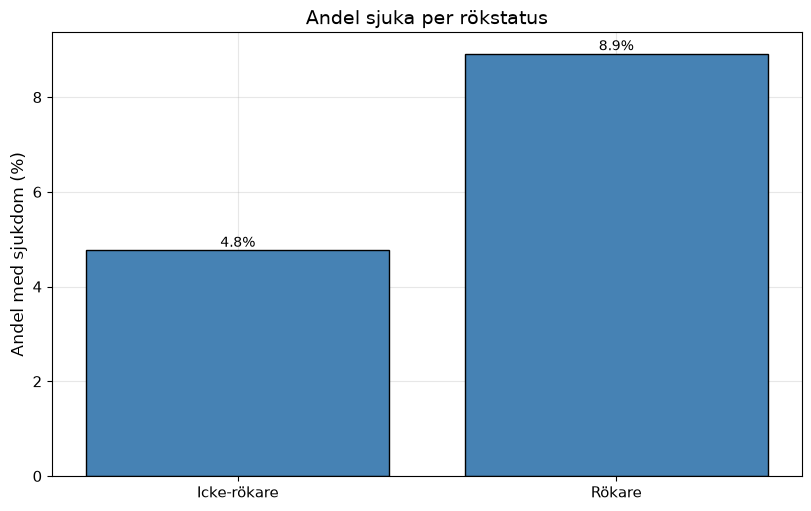

In [26]:
disease_share = df.groupby("smoker")["disease"].mean() * 100
disease_share = disease_share.reindex(["No", "Yes"])

fig, ax = plt.subplots()

bars = ax.bar(["Icke-rökare", "Rökare"], disease_share.values, edgecolor="black")
ax.bar_label(bars, fmt="%.1f%%")

ax.set_title("Andel sjuka per rökstatus")
ax.set_ylabel("Andel med sjukdom (%)")

plt.show()

**Observationer:**
- Blodtrycksfördelningen är ungefär normal, vilket syns på den klockformade kurvan och på att medelvärdet och medianen ligger mycket nära varandra mitt i diagrammet.
- Boxplotten över vikt visar några extremvärden, men eftersom de ligger nära resten av datan verkar de inte vara felaktiga mätvärden.
- Rökare utgör ca 26,6 % av deltagarna.
- Andelen sjuka skiljer sig mellan rökare (8,9%) och icke-rökare (4,8%), men eftersom det bara finns 47 sjukdomsfall i datasetet krävs ytterligare analys för att kunna bekräfta eller avfärda ett samband mellan rökning och sjukdom.

## 4. Andel sjuka och simulering

Först beräknas andelen deltagare med sjukdomen i datasetet. Därefter simuleras 1000 slumpade personer där var och en har samma sannolikhet att vara sjuk som den observerade andelen. Syftet är att se hur mycket en andel från ett slumpmässigt stickprov av den storleken kan avvika från den "sanna" sannolikheten.

**moguce dodati grafik posle ovoga, ali nije neophodno za zadatak**

In [27]:
disease_proportion = df["disease"].mean()
n_diseased = df["disease"].sum()

print(f"Antal sjuka i datasetet: {n_diseased} av {len(df)}")
print(f"Andel sjuka i datasetet: {disease_proportion:.4f} ({disease_proportion * 100:.2f} %)")

np.random.seed(42)
n_simulated = 1000
simulated_disease = np.random.binomial(n=1, p=disease_proportion, size=n_simulated)

simulated_proportion = simulated_disease.mean()

print(f"Antal sjuka i simuleringen: {simulated_disease.sum()} av {n_simulated}")
print(f"Andel sjuka i simuleringen: {simulated_proportion:.4f} ({simulated_proportion * 100:.2f} %)")
print(f"Skillnad (simulerad - verklig): {(simulated_proportion - disease_proportion) * 100:.2f} procentenheter")

Antal sjuka i datasetet: 47 av 800
Andel sjuka i datasetet: 0.0587 (5.88 %)
Antal sjuka i simuleringen: 56 av 1000
Andel sjuka i simuleringen: 0.0560 (5.60 %)
Skillnad (simulerad - verklig): -0.27 procentenheter


## 5. Konfidensintervall för medelvärdet av systolic_bp

Ett 95 %-igt konfidensintervall för medelblodtrycket beräknas med två metoder:

1. **Normalapproximation:** medelvärde ± 1,96 · standardfel, där standardfelet är s / √n. Eftersom stickprovet är stort, det kritiska z-värdet 1,96 används här istället för t-intervallet.
2. **Bootstrap:** stickprovet dras om med återläggning många gånger,
   medelvärdet beräknas för varje omdragning, och intervallet tas från den 2,5:e och 97,5:e percentilen av dessa medelvärden.

Resultaten jämförs därefter.

In [28]:
# Normalapproximation

bp = df["systolic_bp"].to_numpy()
n = len(bp)

bp_mean = bp.mean()
bp_std = bp.std(ddof=1)
standard_error = bp_std / np.sqrt(n)

z_critical = 1.96
ci_normal = (bp_mean - z_critical * standard_error,
             bp_mean + z_critical * standard_error)

print(f"Medelvärde: {bp_mean:.2f} mmHg")
print(f"Standardfel: {standard_error:.3f}")
print(f"95 % CI (normalapproximation): [{ci_normal[0]:.2f}, {ci_normal[1]:.2f}]")

Medelvärde: 149.18 mmHg
Standardfel: 0.452
95 % CI (normalapproximation): [148.29, 150.07]


In [29]:
# Bootstrap

np.random.seed(42)
n_bootstrap = 10000

bootstrap_means = np.empty(n_bootstrap)
for i in range(n_bootstrap):
    resample = np.random.choice(bp, size=n, replace=True)
    bootstrap_means[i] = resample.mean()

ci_bootstrap = tuple(np.percentile(bootstrap_means, [2.5, 97.5]))

print(f"Bootstrap-standardfel: {bootstrap_means.std(ddof=1):.3f}")
print(f"95 % CI (bootstrap): [{ci_bootstrap[0]:.2f}, {ci_bootstrap[1]:.2f}]")

Bootstrap-standardfel: 0.450
95 % CI (bootstrap): [148.30, 150.07]


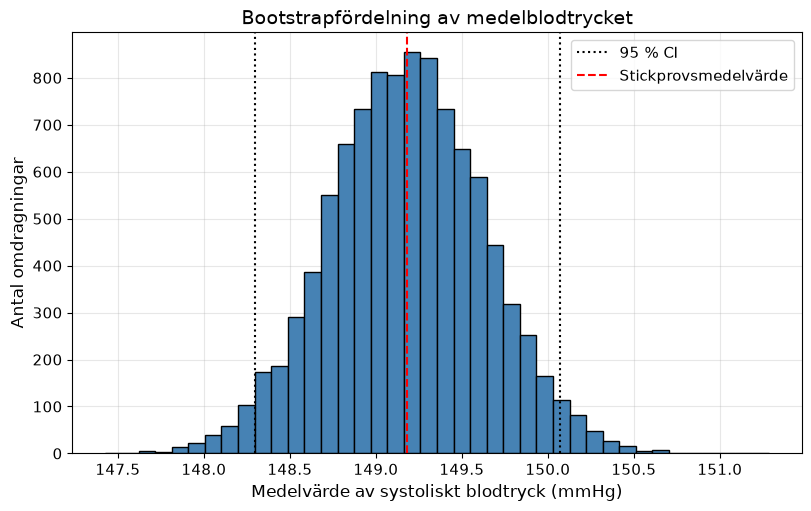

In [30]:
fig, ax = plt.subplots()
ax.hist(bootstrap_means, bins=40, edgecolor="black")
ax.axvline(ci_bootstrap[0], color="black", linestyle=":", label="95 % CI")
ax.axvline(ci_bootstrap[1], color="black", linestyle=":")
ax.axvline(bp_mean, color="red", linestyle="--", label="Stickprovsmedelvärde")

ax.set_title("Bootstrapfördelning av medelblodtrycket")
ax.set_xlabel("Medelvärde av systoliskt blodtryck (mmHg)")
ax.set_ylabel("Antal omdragningar")
ax.legend()
plt.show()

In [31]:
comparison = pd.DataFrame(
    {
        "Nedre gräns": [ci_normal[0], ci_bootstrap[0]],
        "Övre gräns": [ci_normal[1], ci_bootstrap[1]],
    },
    index=["Normalapproximation", "Bootstrap"],
)
comparison["Bredd"] = comparison["Övre gräns"] - comparison["Nedre gräns"]

display(comparison.round(3))

,Nedre gräns,Övre gräns,Bredd
Normalapproximation,148.292,150.065,1.773
Bootstrap,148.297,150.073,1.776


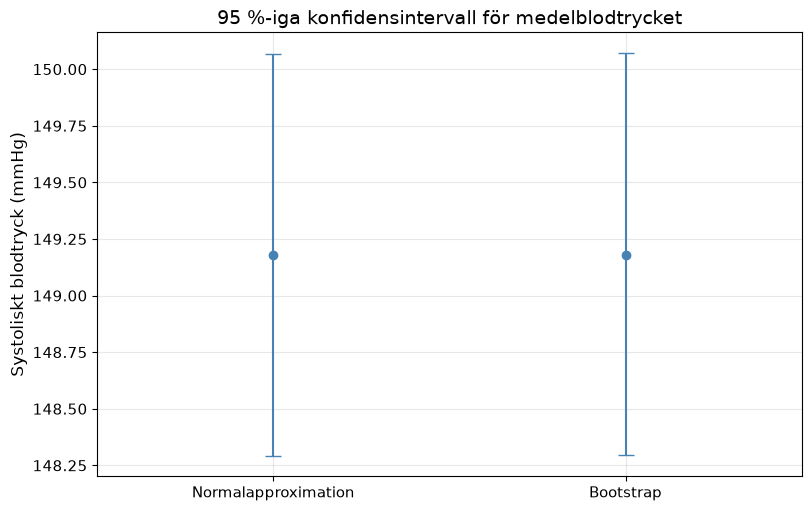

In [32]:
labels = ["Normalapproximation", "Bootstrap"]
intervals = [ci_normal, ci_bootstrap]

lower_errors = [bp_mean - lo for lo, hi in intervals]
upper_errors = [hi - bp_mean for lo, hi in intervals]

fig, ax = plt.subplots()
ax.errorbar([0, 1], [bp_mean, bp_mean], yerr=[lower_errors, upper_errors],
            fmt="o", capsize=6)

ax.set_xticks([0, 1])
ax.set_xticklabels(labels)
ax.set_xlim(-0.5, 1.5)

ax.set_title("95 %-iga konfidensintervall för medelblodtrycket")
ax.set_ylabel("Systoliskt blodtryck (mmHg)")
plt.show()

**Jämförelse av metoderna:**

- Grafen visar medelvärdet av systoliskt blodtryck med 95 %-iga konfidensintervall beräknade med normalapproximation och bootstrap, och intervallen är nästan identiska. Med båda metoderna ligger intervallet på ungefär 148,3 till 150,1 mmHg, med ett medelvärde på ca 149,2 mmHg, vilket är ett rimligt spann för det verkliga medelblodtrycket.
- Det är väntat eftersom stickprovet är stort (n = 800). Då fungerar normalapproximationen bra enligt centrala gränsvärdessatsen, och bootstrapfördelningen av medelvärdet blir också nära normalfördelad.
- I det här fallet påverkar valet av metod inte slutsatsen.

## 6. Hypotesprövning: har rökare högre medelblodtryck?

Enligt analysplanen testas följande hypoteser för systolic_bp:

- **H₀:** Rökare och icke-rökare har samma medelblodtryck (μ_rökare = μ_icke-rökare).
- **H₁:** Rökare har högre medelblodtryck än icke-rökare (μ_rökare > μ_icke-rökare).

Testet är ensidigt eftersom hypotesen har en bestämd riktning, och signifikansnivån är
α = 0,05. Skillnaden beräknas som rökare minus icke-rökare. Testet genomförs med två
metoder (Welchs t-test och bootstrap under H₀). Därefter beräknas ett konfidensintervall
för skillnaden, effektstorleken Cohens d samt en känslighetsanalys där extremvärden
tas bort.

In [33]:
group_stats = df.groupby("smoker")["systolic_bp"].agg(["count", "mean", "median", "std", "min", "max"])
display(group_stats.round(2))

smoker_bp = df.loc[df["smoker"] == "Yes", "systolic_bp"].to_numpy()
nonsmoker_bp = df.loc[df["smoker"] == "No", "systolic_bp"].to_numpy()

obs_diff = smoker_bp.mean() - nonsmoker_bp.mean()
print(f"Observerad skillnad (rökare - icke-rökare): {obs_diff:.2f} mmHg")

,count,mean,median,std,min,max
smoker,,,,,,
No,587,149.05,149.3,12.63,116.3,185.9
Yes,213,149.52,149.5,13.27,106.8,184.2


Observerad skillnad (rökare - icke-rökare): 0.47 mmHg


In [ ]:
# Manuellt Welch t-test

var_smoker = smoker_bp.var(ddof=1)
var_nonsmoker = nonsmoker_bp.var(ddof=1)
n_smoker, n_nonsmoker = len(smoker_bp), len(nonsmoker_bp)

se_diff = np.sqrt(var_smoker / n_smoker + var_nonsmoker / n_nonsmoker)

t_manual = obs_diff / se_diff

df_num = (var_smoker / n_smoker + var_nonsmoker / n_nonsmoker) ** 2
df_den = (var_smoker**2 / ((n_smoker**2) * (n_smoker - 1))
          + var_nonsmoker**2 / ((n_nonsmoker**2) * (n_nonsmoker - 1)))
df_welch = df_num / df_den

print(f"Skillnadens standardfel: {se_diff:.3f}")
print(f"t (manuell): {t_manual:.3f}")
print(f"Frihetsgrader (Welch): {df_welch:.1f}")

Standardfel: 1.048
t (manuell): 0.450
Frihetsgrader (Welch): 360.2


In [ ]:
# Scipy test - bekräftelse av det manuella testet

result = stats.ttest_ind(smoker_bp, nonsmoker_bp, equal_var=False, alternative="greater")

print(f"Welch t-test (ensidigt): t = {result.statistic:.3f}, p = {result.pvalue:.4f}")

Welch t-test (ensidigt): t = 0.450, p = 0.3264


In [ ]:
# Bootstrap centrerad till nollskillnad

def null_shifted_bootstrap_p(group_a, group_b, n_boot=10_000):
    """One-sided null-shifted bootstrap test of H1: mean(group_a) > mean(group_b).

    Both groups are shifted to the pooled mean so that H0 is true, then resampled
    with replacement. Returns the p-value and the simulated differences.
    """
    observed = group_a.mean() - group_b.mean()
    grand_mean = np.concatenate([group_a, group_b]).mean()

    a0 = group_a - group_a.mean() + grand_mean
    b0 = group_b - group_b.mean() + grand_mean

    boot_diffs = np.empty(n_boot)
    for i in range(n_boot):
        a_star = np.random.choice(a0, size=len(a0), replace=True)
        b_star = np.random.choice(b0, size=len(b0), replace=True)
        boot_diffs[i] = a_star.mean() - b_star.mean()

    return np.mean(boot_diffs >= observed), boot_diffs


np.random.seed(42)
p_boot_null, boot_null_diffs = null_shifted_bootstrap_p(smoker_bp, nonsmoker_bp)

print(f"Observerad skillnad: {obs_diff:.2f} mmHg")
print(f"P-värde (bootstrap under H0, ensidigt): {p_boot_null:.4f}")

Observerad skillnad: 0.47 mmHg
P-värde (bootstrap under H0, ensidigt): 0.3331


In [ ]:
# Konfidensintervall för skillnaden med vanlig bootstrap
np.random.seed(42)
n_boot = 10_000
boot_diffs = np.empty(n_boot)
for i in range(n_boot):
    smoker_star = np.random.choice(smoker_bp, size=n_smoker, replace=True)
    nonsmoker_star = np.random.choice(nonsmoker_bp, size=n_nonsmoker, replace=True)
    boot_diffs[i] = smoker_star.mean() - nonsmoker_star.mean()

ci_low, ci_high = np.percentile(boot_diffs, [2.5, 97.5])
print(f"95 % CI för skillnaden (bootstrap): [{ci_low:.2f}, {ci_high:.2f}] mmHg")

# Cohen's d
pooled_std = np.sqrt(((n_smoker - 1) * var_smoker + (n_nonsmoker - 1) * var_nonsmoker)
                     / (n_smoker + n_nonsmoker - 2))
cohens_d = obs_diff / pooled_std
print(f"Cohens d: {cohens_d:.3f}")

95 % CI för skillnaden (bootstrap): [-1.63, 2.51] mmHg
Cohens d: 0.037


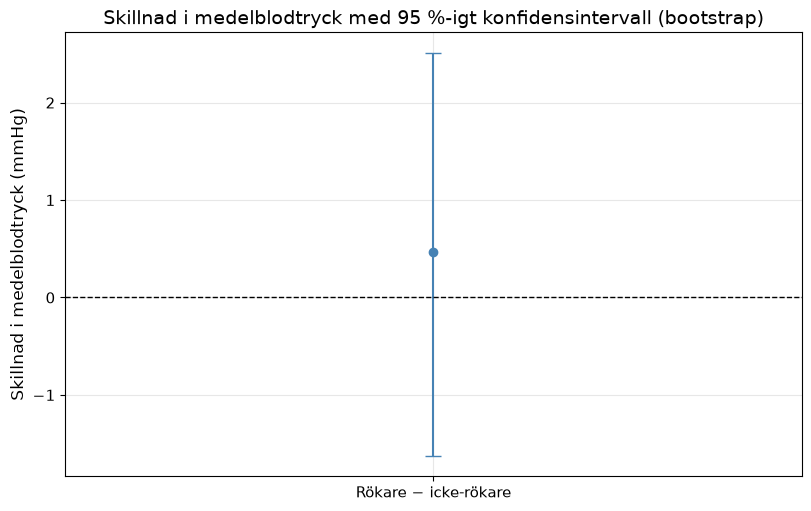

In [38]:
fig, ax = plt.subplots()
ax.errorbar([0], [obs_diff], yerr=[[obs_diff - ci_low], [ci_high - obs_diff]],
            fmt="o", capsize=6)
ax.axhline(0, color="black", linestyle="--", linewidth=1)
ax.set_xticks([0])
ax.set_xticklabels(["Rökare − icke-rökare"])
ax.set_ylabel("Skillnad i medelblodtryck (mmHg)")
ax.set_title("Skillnad i medelblodtryck med 95 %-igt konfidensintervall (bootstrap)")
plt.show()

**Förklaring av testresultaten:**

- **Standardfel:** Ca 1,05 mmHg, medan den observerade skillnaden är ca 0,47 mmHg. Standardfelet är alltså större än skillnaden, vilket betyder att skillnaden ryms inom den variation som slumpen normalt ger mellan stickprov och inte går att urskilja från bruset.
- **t-värde:** Värdet på ca 0,45 är mycket lågt. Den observerade skillnaden ligger bara 0,45 standardfel från noll, vilket är långt under gränsen på ca 1,65 för ett ensidigt test med α = 0,05.
- **Frihetsgrader (Welch):** Det stora antalet frihetsgrader (ca 360) gör att t-fördelningen i praktiken är densamma som normalfördelningen.
- **P-värde:** Ca 0,33. Om H₀ vore sann skulle en skillnad som är minst lika stor som den observerade uppstå i ungefär en tredjedel av alla stickprov enbart av slumpen. Datan är alltså helt vanlig under H₀.
- **Bootstraptest med förskjutning under H₀:** P-värdet är nästan detsamma som för t-testet, vilket stärker slutsatsen eftersom de två metoderna bygger på olika antaganden.
- **Konfidensintervall för skillnaden (vanlig bootstrap):** Intervallet visar hur stor skillnaden rimligen kan vara. Med ett intervall på ca −1,6 till +2,5 mmHg ingår 0, vilket betyder att 0 är ett rimligt värde för skillnaden. Intervallet innehåller dessutom både positiva och negativa värden, så datan kan inte avgöra åt vilket håll en eventuell skillnad går.
- **Cohens d:** Visar effektens storlek oberoende av stickprovets storlek. Ett värde på ca 0,04 räknas som en mycket liten effekt (tumregel: 0,2 liten, 0,5 medel, 0,8 stor).

**Slutsats:** Utifrån samtliga resultat kan H₀ inte förkastas vid α = 0,05. Inga belägg har hittats för att rökare har högre medelblodtryck än icke-rökare. Detta bevisar inte att ingen skillnad finns, utan endast att datan är förenlig med ingen skillnad, och en liten skillnad åt endera håll kan inte uteslutas. Den observerade skillnaden på ca 0,47 mmHg ligger också långt under den praktiskt betydelsefulla skillnaden enligt analysplanen (5 mmHg). Även intervallets övre gräns (ca 2,5 mmHg) ligger under denna nivå. Eftersom datan är observationell kan resultatet i vilket fall inte visa att rökning orsakar (eller inte orsakar) högre blodtryck. Om testet har tillräcklig styrka för att upptäcka en betydelsefull skillnad undersöks med powersimulering.